# Rabbits and foxes, by kinetic Monte Carlo

**CHME 5137, Lecture 10, Tuesday October 13, 2026.** Started in class, finished for
homework.

*Written for 2026 by Claude Code (Claude Opus 5.5) from Prof. West's KMC question of
earlier years, and checked by Prof. West. The problem is from Chapter 1 of H. Scott
Fogler's "Essentials of Chemical Reaction Engineering".*

---

Same farm, same rate constants: 400 rabbits and 200 foxes at the start, and

$$\frac{dR}{dt} = k_1 R - k_2 R F \qquad\qquad \frac{dF}{dt} = k_3 R F - k_4 F$$

with $k_1 = 0.015$ day$^{-1}$, $k_2 = 0.00004$ day$^{-1}$ foxes$^{-1}$,
$k_3 = 0.0004$ day$^{-1}$ rabbits$^{-1}$ and $k_4 = 0.04$ day$^{-1}$.

In the `solve_ivp` homework you found that the foxes fall to **under two** in each
trough. The ODEs don't mind: 1.6 foxes carry on and breed. Real foxes can't be
fractional, and two foxes can easily both die before they meet a rabbit. So now we
treat every rabbit and fox as an individual, and every birth and death as a random
event. That is **kinetic Monte Carlo** (KMC).

### The events

There are four events. Each has a rate, in events per day, which changes as the
populations change:

| Event | Rate | Effect |
|---|---|---|
| a rabbit is born | $k_1 R$ | $R \to R + 1$ |
| a rabbit is eaten | $k_2 R F$ | $R \to R - 1$ |
| a fox is born | $k_3 R F$ | $F \to F + 1$ |
| a fox dies | $k_4 F$ | $F \to F - 1$ |

The rates are easy to calculate, so we use the **rejection-free** algorithm, which you
worked out in class from
[Wikipedia's Kinetic Monte Carlo page](https://en.wikipedia.org/wiki/Kinetic_Monte_Carlo).
Writing it down in your own words is the first part of task 1.

### How to work

- **Commit as you go.** After each numbered task works, Restart & Run All, then
  stage, commit with a message that says what you did, and push. At least one commit
  per task. Your commit history is part of what gets looked at. **Commit the `.ipynb`
  and its paired `.py` together**: the `.py` is the one whose diffs you can read on
  GitHub. If saving the notebook doesn't update the `.py`, see *Setting up Jupytext* on
  Canvas.
- **Answer the questions in words**, in the markdown cells marked *Answer*.
  Double-click a cell to edit it.
- **Random numbers:** use a NumPy generator, `rng = np.random.default_rng(seed)`,
  not the legacy `np.random.*` functions. Give it a seed, so that Restart & Run All
  gives the same answers every time. Check what interval each function returns,
  and what its arguments mean, before you trust it.
- **Let bugs shout.** If a population goes negative or an event isn't one of the
  four, `raise` an error. Don't hide it with `max(0, F)`: that turns a bug you'd
  notice into a wrong answer you won't.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

k1 = 0.015  # 1/day
k2 = 0.00004  # 1/day/fox
k3 = 0.0004  # 1/day/rabbit
k4 = 0.04  # 1/day

R0, F0 = 400, 200  # rabbits and foxes at t = 0
t_end = 600  # days

The deterministic answer, for comparison. This is the `solve_ivp` homework's
solution, at a tight tolerance.

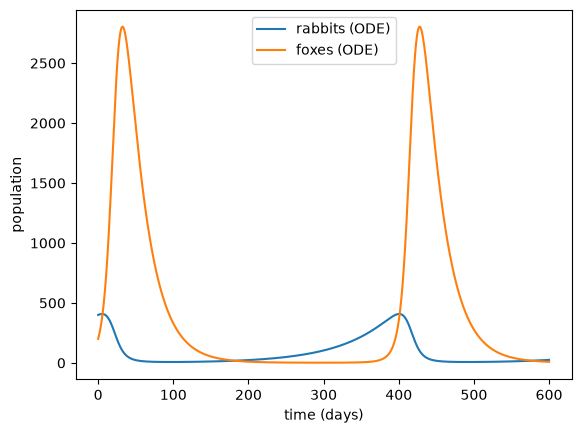

In [2]:
def dydt(t, y):
    R, F = y
    return [k1 * R - k2 * R * F, k3 * R * F - k4 * F]

ode = solve_ivp(dydt, (0, t_end), [R0, F0], rtol=1e-10, atol=1e-8, dense_output=True)
t_ode = np.linspace(0, t_end, 3001)
R_ode, F_ode = ode.sol(t_ode)

plt.plot(t_ode, R_ode, label="rabbits (ODE)")
plt.plot(t_ode, F_ode, label="foxes (ODE)")
plt.xlabel("time (days)")
plt.ylabel("population")
plt.legend()
plt.show()

## 1. One trajectory

**(a) The algorithm, in your own words.** Before you write any code, write the
rejection-free algorithm as numbered steps, for rabbits and foxes: what each of
Wikipedia's symbols ($k$, $r_{ki}$, $R_{ki}$, $Q_k$, $u$, $u'$) becomes here, how the
next event is chosen, and how far the clock moves. Then work the **first step by
hand**, from 400 rabbits and 200 foxes, with $u = 0.5$ and $u' = 0.3$: which event
happens, and how many minutes pass?

*Answer:*

1) Define a list of times, starting at $t = 0$

2) Define the initial state for the system in quesiton as $k$

3) Define a list $N_{k}$ of transition rates $r_{ki}$ where the number of transition rates is equal to the number of unique events that can evolve state $k$

4) Calculate $R_{ki}$ as a cumulative summing function for all $r_{ki}$ in $N_{k}$...
    
    The dimensionaliy of $R_{ki}$ = dimensionality of $N_{k}$
    
    Consider an $N_{k}$ list of 4 $r_{k}$ values:
    
    $R_{k1} = r_{k1}$
    
    $R_{k2} = r_{k1}+r_{k2}$

    ...
    
    $R_{kn} = r_{k1}+r_{k2}+...r_{kn}$
    

    Also calculate the total rate $Q_{k}$ = $R_{k,N_{k}}$ which is that final $R_{kn}$ value

5) Randomly select a uniform number $u$ from 0 to 1

6) Define probabilities as uniform regions along a number line from 0 to 1 with each uniform region representing the odds of state k going through any particular transition state.

7) Carry out the event that was randomly selected from the probability distrbution such that state k goes to state i.

8) Randomly select a new uniform number $u'$

9) Update the time in the simulation to $t = t_{i} + Δt$ where $\Delta t = Q_{k}^{-1} \ln\left(\frac{1}{u'}\right)$

10) Loop back into step 3 and repeat.





## Part a-2: Hand Calculation -look above - dont forget!





**(b) The function.** Write

```python
def kmc(R0, F0, t_end, rng):
    ...
    return times, rabbits, foxes   # three NumPy arrays, one entry per event
```

that runs your algorithm from $t = 0$ until the clock passes `t_end`. If the total
rate is ever zero, nothing more can happen, so stop there.

Run it once. How many events were there, and how long did it take? Plot rabbits and
foxes against time, on top of the ODE solution. (`plt.step(times, foxes, where="post")`
draws a population that jumps, rather than one that slopes.) Run it a few more times
with different seeds. How does a KMC trajectory differ from the ODE solution?

[0, 0.01845, 0.01934, 0.03774, 0.08654, 0.09079, 0.09751, 0.11493, 0.1302, 0.14403, 0.15753, 0.23337, 0.24102, 0.27249, 0.2828, 0.28556, 0.28723, 0.30793, 0.34266, 0.35706, 0.36208, 0.37016, 0.40925, 0.41861, 0.47846, 0.49527, 0.49836, 0.51419, 0.51808, 0.51946, 0.52159, 0.53468, 0.53611, 0.54083, 0.55014, 0.57868, 0.59911, 0.61951, 0.6613, 0.66518, 0.69027, 0.70067, 0.71789, 0.73057, 0.74757, 0.7914, 0.79953, 0.8202, 0.83272, 0.84504, 0.90188, 0.9084, 0.90841, 0.91395, 0.91421, 0.94372, 0.96916, 0.99428, 1.02763, 1.08051, 1.10099, 1.11741, 1.15817, 1.16695, 1.18881, 1.19761, 1.20615, 1.21094, 1.219, 1.26428, 1.27208, 1.28062, 1.2862, 1.29544, 1.30606, 1.33069, 1.36707, 1.37301, 1.38109, 1.4473, 1.48461, 1.5055, 1.50901, 1.52326, 1.5567, 1.58789, 1.65279, 1.65324, 1.69843, 1.70569, 1.75982, 1.80596, 1.81771, 1.82985, 1.85504, 1.86944, 1.89077, 1.90045, 1.91587, 1.93758, 1.96336, 1.97449, 1.98407, 1.98554, 1.99496, 1.99855, 1.99956, 2.01799, 2.02926, 2.08125, 2.08563, 2.10914, 2.12076, 

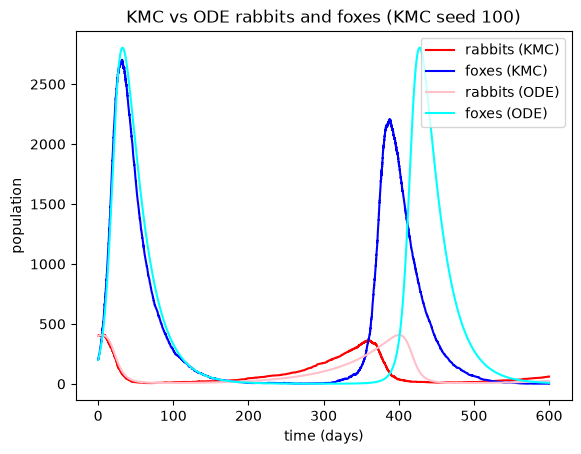

In [3]:
def kmc(R0, F0, t_end, rng, s):
    """This function runs a kinetic monte carlo algorithm for a two-species (rabbit/fox) system"""
    #Defining the parameters 
    k1 = 0.015 # in days^-1
    k2 = 0.00004 
    k3 = 0.0004 
    k4 = 0.04 
    # Steps 1 & 2 
    t = [0]
    R = [R0]
    F = [F0]
    rng = np.random.default_rng(seed = s)
    
    # Start of Loop (steps 3-9)
    while t[-1] < t_end:
        r = R[-1]   # current rabbits
        f = F[-1]   # current foxes
        
        # Step 3
        N_k = [k1*r, k2*r*f, k3*r*f, k4*f] 

        # Step 4
        R_ki = [k1*r, k1*r+k2*r*f, k1*r+k2*r*f+k3*r*f, sum(N_k)] 
        Q = sum(N_k)
        if Q == 0:
            break

        # Step 5
        u = 1 - rng.random()

        # Step 6 - Binary Search Algorithm 
        target = u*Q
        low = 0
        high = len(R_ki)
        while low < high:
            mid = (low + high) // 2
            if R_ki[mid] < target:
                low = mid + 1
            else:
                high = mid
        i = low

        # Step 7 
        if i == 0:
            r = r + 1
        elif i == 1:
            r = r - 1
        elif i == 2:
            f = f + 1
        else:
            f = f - 1

        # Step 8 
        u_prime = 1 - rng.random()

        # Step 9
        Δt = (1/Q)*np.log(1/u_prime)
        if t[-1] + Δt > t_end:
            t.append(t_end)
            R.append(R[-1])   # old counts: the event didn't happen in time
            F.append(F[-1])
            break
        t.append(round(float(t[-1] + Δt),ndigits = 5))
        R.append(r)
        F.append(f)
    return t, R, F
rng = np.random.default_rng()
t, R, F = kmc(R0 = 400, F0 = 200, t_end = 600, rng = rng, s =100)
print(t)
print(R)
print(F)
print(len(t))
print(t[-1])
plt.plot(t, R, "red", label="rabbits (KMC)")
plt.plot(t, F, "blue", label="foxes (KMC)")
plt.plot(t_ode, R_ode, "pink", label="rabbits (ODE)")
plt.plot(t_ode, F_ode, "cyan",label="foxes (ODE)")
# plt.step(t, F, where="post")
plt.xlabel("time (days)")
plt.ylabel("population")
plt.legend()
plt.title(f"KMC vs ODE rabbits and foxes (KMC seed {100})")
plt.show()

*Answer:* There were 1100 events spanning 150.75482 days at seed 550.  The KMC trajectory varries from the ODE one in the sense that extinction events are possible outcomes.  In this particular seed, foxes goes extinct early on and so the rabbit population explodes.

## 2. Many trajectories, and where they end up

Plot the foxes from 20 trajectories on one graph (thin lines, `lw=0.5`), with the ODE
solution on top.

- What do the trajectories have in common, and where do they spread apart?
- What happens to a trajectory once the foxes reach zero? Once the rabbits reach
  zero? Why can't it ever recover?
- Where in the cycle do the foxes usually die out, and why there? (Your answer to
  task 5 of the `solve_ivp` homework is relevant.)

20
14710
14710
14710
dimensions: 0, type: <class 'dict'>
20
(3, 14710)


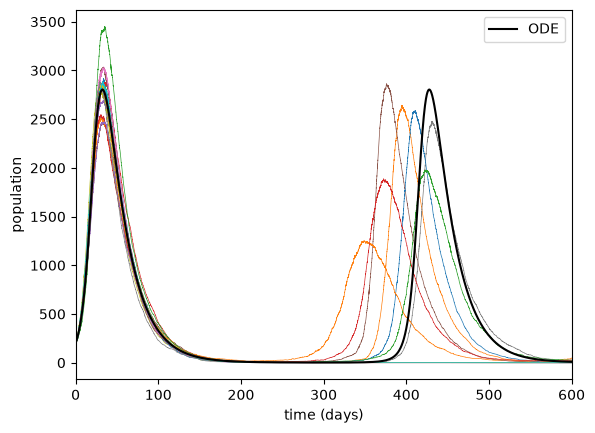

In [ ]:
def seed_trajectory_scan(span, t_end):
    "This function creates a dictionary of elements = span"
    runs = {}
    for s in range(span):
        rng = np.random.default_rng(seed = s)
        t, R, F = kmc(R0=400, F0=200, t_end = 600, rng=rng, s=s)
        runs[s] = np.array([t,R,F]) #this defines runs as a 3Xs matrix where t is the 0th element, R is the 1st, and F is the 2nd
        plt.plot(t, F, lw = 0.5)
    plt.xlim(0,t_end)
    plt.xlabel("time (days)")
    plt.ylabel("population")
    plt.plot(t_ode, F_ode, "black", label = "ODE")
    plt.legend()
    return runs
results = seed_trajectory_scan(span = 20, t_end = 600);
print(len(results))
print(len(results[0][0]))
print(len(results[0][1]))
print(len(results[0][2]))
print(f"dimensions: {np.ndim(results)}, type: {type(results)}")
print(len(results))
print(results[0].shape)

*Answer:*  All of the trajectories converge towards 0 and have similar changes in slope.  But their population maximums are slightly different.  The trajectory of all foxes stay at zero when the population reaches zero because once F=0 the $N_{k}$ list goes to just the $k_{1}*R$ term so the transition probabilities resolve to just rabbit growth.

## 3. The second fox peak

The ODE's foxes peak at about day 32, and again at about day 428, at about 2804
foxes each time. When is the second peak in a KMC trajectory, and how high?

A noisy trajectory has lots of tiny local maxima, so we need a definition. Use this
one: **the largest number of foxes after day 200, counted as a peak only if it is
above 100 foxes and isn't within 5 days of either end of the window** (day 200 or
day 600). Write a function `second_peak(times, foxes)` that returns `(time, height)`,
or `None` if there isn't one.

Run 100 trajectories for parts a-f...

*Answer:*  

a) In what fraction is there a second peak? 

- 33%

b) For those that have one, give the mean and median of its time and of its height, and the interquartile
range (25th to 75th percentile, `np.percentile`) of each. Plot histograms.

- Use the lines below to see the mean, medians, and interquartile ranges for the filtered times and heights.

c) How do these compare with the ODE's second peak? 

- They usually lead ahead of the ODE peak and their peaks are usually lower.

d) If they differ, why?

- The peaks usually lead because in KMC simulations foxes can't fall below a population of 1.  Meaning when the foxes survive, they can build up faster relative to ODE simulations where foxes also survive.  Similarly, the KMC fox peaks are usually smaller because the rabbit population is smaller in the KMC simulation.  It's a long winded way of saying that because the KMC simulation can't model fractions of a object, the surival loops for foxes and rabbits are tighter.

e) And what does the definition get wrong? 

- I'm a little confused by this question - looking at the results, the constraints of the second peak scan capture every second peak for 100 seeds.  If you mean conceptually the definition of the constaints could ommit a real bump sure that's possible.  However I'm not sure how to even explore wether these models capture steady state equilibrium so my understanding of the "definition" is quite limited.  I will say it's possible that different initial fox and rabbit conditions could force the peaks to shift in time and so to some degree the time window constraint could fail when assessing families of solutions.

f) Find a trajectory where it picks something you wouldn't call "the second peak", if you can.

- I couldn't find anything.  It could be possible that the phasing of rabbits and foxes are offset such that the fox peak doesn't reach it potential maximum. 

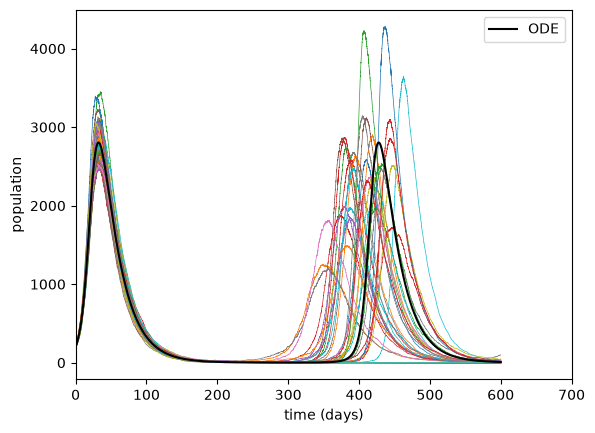

In [72]:
results = seed_trajectory_scan(span = 100, t_end = 700);

In [78]:
def second_peak_filter(data, x_row, y_row, t_min, t_max, λ, y_min):
    #creates the lists we want to fill after scanning
    peak_times = []
    peak_heights = []
    for s in data:
        # From the way the seed_trajectory_scan function is defined, we want to extract rows 0 = t and 2 = foxes
        t = data[s][x_row]   # Sets t as the vector selected from x_row
        F = data[s][y_row]   # Sets F as the vector selected from y_row of 
        window = (t >= t_min) & (t <= t_max)            # This stages the constraints for the time window
        if not window.any():                            # skips a seed if there's no time value that fits within the window
            continue
        max = np.argmax(F[window])                        # max is the biggest value in window
        t_pk, F_pk = t[window][max], F[window][max]
        if F_pk > y_min and t_min + λ <= t_pk <= t_max - λ:   # This stages the conditions for the peak edges and the fox minimum
            peak_times.append(t_pk)                           # This appends values to the peak list 
            peak_heights.append(F_pk)                         # This appends values to the peak list 
    return np.array(peak_times), np.array(peak_heights)
peak_times, peak_heights = second_peak_filter(data=results, x_row=0, y_row=2, t_min=200, t_max=600, λ=5, y_min=100)
filtered_results = second_peak_filter(data=results, x_row=0, y_row=2, t_min=200, t_max=600, λ=5, y_min=100)
print(len(peak_times))
print(len(peak_heights))
print(len(filtered_results))
print(len(filtered_results[0]))
print(len(filtered_results[1]))

33
33
2
33
33


33.0 %
time (days): mean 405.0, median 406.8,IQR 381.2–423.8 (width 42.6)
Fox height (population #): mean 2507.5, median 2515.0,IQR 1978.0–2862.0 (width 884.0)


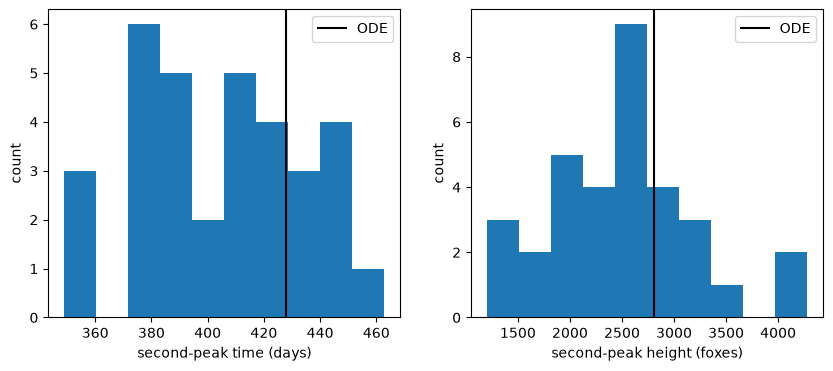

In [ ]:
# Converting tthe percentage of seeds that had a verifed second peak
s = 100
print(f"{(len(peak_heights)/s)*100} %")


for name, x in [("time (days)", peak_times), ("Fox height (population #)", peak_heights)]:
    q25, q75 = np.percentile(x, [25, 75])
    print(f"{name}: mean {x.mean():.1f}, median {np.median(x):.1f}," f"IQR {q25:.1f}–{q75:.1f} (width {q75 - q25:.1f})")
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].hist(peak_times, bins=10)
ax[0].axvline(428, color="black", label="ODE")
ax[0].set_xlabel("second-peak time (days)")
ax[1].hist(peak_heights, bins=10)
ax[1].axvline(2804, color="black", label="ODE")
ax[1].set_xlabel("second-peak height (foxes)")
for a in ax:
    a.set_ylabel("count")
    a.legend()
    a.minorticks_on
plt.show()

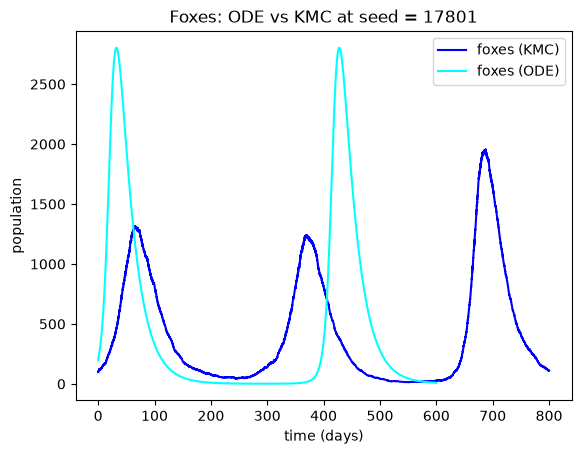

In [80]:
t, R, F = kmc(R0 = 200, F0 = 100, t_end = 800, rng = rng, s = 17801)
plt.plot(t, F, "blue", label="foxes (KMC)")
plt.plot(t_ode, F_ode, "cyan",label="foxes (ODE)")
plt.xlabel("time (days)")
plt.ylabel("population")
plt.title(f"Foxes: ODE vs KMC at seed = {17801}")
plt.legend()
plt.show()

## 4. How many runs are enough?

Every number in task 3 came from random runs, so it has its own uncertainty. Repeat
task 3 with 100, 300, 1000 and 3000 trajectories. (Time it first, and work out how
long 3000 will take before you start.)

- How do the mean second-peak time and height change with the number of runs?
- Work out the **standard error** of each mean, $s / \sqrt{n}$, where $s$ is the
  standard deviation and $n$ the number of trajectories with a peak. How does it
  scale with $n$?
- Give the expected time and height of the second peak, and their interquartile
  ranges, to a precision you can justify. Say how you justified it.

*Answer:*


a) How long will 3000 runs be?

- based on linear regression, I can approximate if every run takes 0.109 seconds.  Therefore, a 3000 trajectory scan will take my computer approximately 5.45 minutes.  

b) How do the mean second peak times and height change with the number of runs?

- Since I wrote my function to test the same span of seeds everytime, the peak height and time don't change with the number of runs.  However, I can say that the times and heights will converge to a more stable value since testing more seeds means having more data to inform each outputs standard deviation.

c) Work out the **standard error** of each mean, $s / \sqrt{n}$, where $s$ is the
  standard deviation and $n$ the number of trajectories with a peak. How does it
  scale with $n$?

- Based on results, standard error vs. runs = [3,0],[100,406.406],[300,414.719], [1000,217.148],[3000,341.209].  Stardard error seems to follow a trend similar to a 2nd order system expereiencing underdamped harmonic oscillation as it relates to the scaling of n.

d) Give the expected time and height of the second peak, and their interquartile ranges, to a precision you can justify. Say how you justified it.

- The expected 2nd peak is t = , h = , std = , IQR = ... I justified the precision is valid because ...


span 1: 0.08 sec
span 2: 0.22 sec
span 3: 0.32 sec
span 4: 0.44 sec
span 5: 0.51 sec
span 10: 1.04 sec
span 15: 1.66 sec
span 20: 2.58 sec
span 30: 3.48 sec
span 50: 5.79 sec


c:\Users\mitch\OneDrive\Desktop\CHME-5137\CHME-5137-Code\kinetic-monte-carlo\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


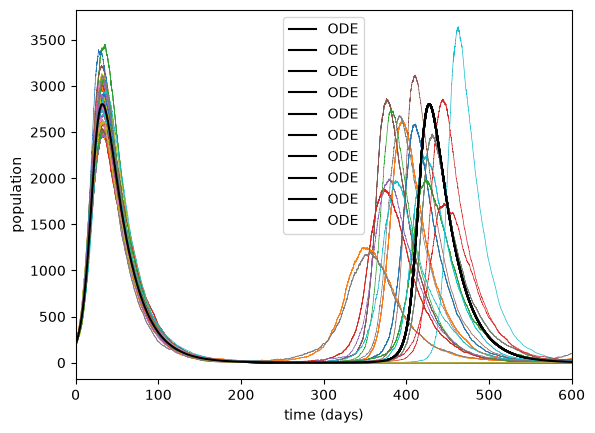

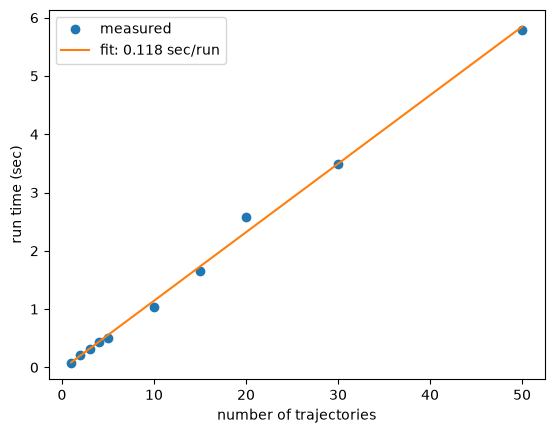

In [109]:
elapsed = {}
spans = [1,2,3,4,5,10,15,20,30,50]
for n in spans:
    start = time.perf_counter()
    seed_trajectory_scan(span=n, t_end=600)
    elapsed[n] = time.perf_counter() - start
    print(f"span {n}: {elapsed[n]:.2f} sec")
plt.figure()                                  # new figure, so it doesn't draw on the scan plots
x = np.array(spans)
y = np.array(list(elapsed.values()))
slope, intercept = np.polyfit(x, y, 1)
plt.plot(x, y, "o", label="measured")
plt.plot(x, slope*x + intercept, "-", label=f"fit: {slope:.3f} sec/run")
plt.xlabel("number of trajectories")
plt.ylabel("run time (sec)")
plt.legend()
plt.show()

The results object should be a dictoionary of length 3 and the first element list is the seed whereas the second element is time[0], rabbits[0], then foxes[0].  To get a standard error, I will need the mean of the filtered peaks from the results and then divide by the span number. 

```python
print(results_3[2][0])
```
```text
output:
[0.0000000e+00 7.2100000e-03 9.1600000e-03 ... 5.9993008e+02 5.9996392e+02
 6.0000000e+02]
```

The filtered results produces an object of length 2 with two rows the first being the mean time(s) and the second being the mean height(s).


The analyzed_filtered results produces an object of length 2 with the first row being mean heigh [0] and the second row being standard deviation of height [1]

mean = 2642.000, std = 0.000, standard error = 0.000


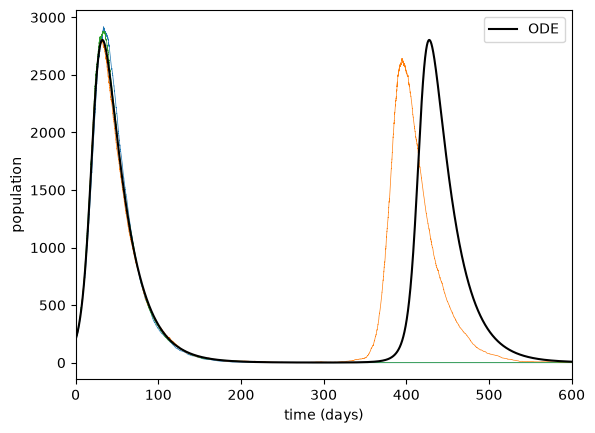

In [196]:
results_3 = seed_trajectory_scan(span =3, t_end = 600)
filtered_results_3 = second_peak_filter(data = results_3, x_row = 0, y_row = 2, t_min = 200, t_max = 600, λ = 5, y_min = 100)

def analysis(data, row, n):
    avg_y = np.mean(data[row])
    std_y = np.std(data[row])
    standard_error = std_y/np.sqrt(n)
    print(f"mean = {avg_y:.3f}, std = {std_y:.3f}, standard error = {standard_error:.3f}")
    return avg_y, std_y, standard_error
analyzed_filtered_results_3 = analysis(data = filtered_results_3, row =1, n = 3)

mean = 2507.545, std = 703.916, standard error = 70.392


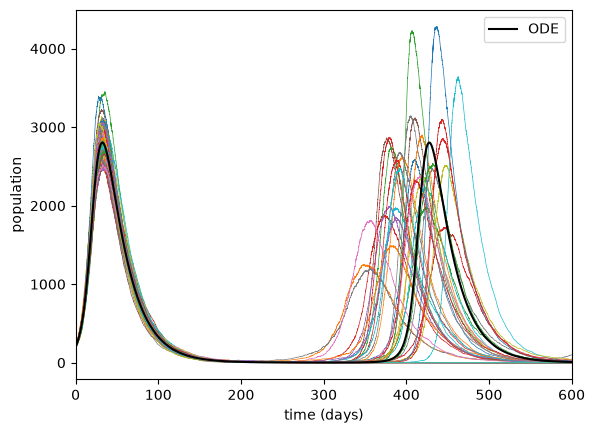

In [197]:
results_100 = seed_trajectory_scan(span = 100, t_end = 600)
filtered_results_100 = second_peak_filter(data = results_100, x_row = 0, y_row = 2, t_min = 200, t_max = 600, λ = 5, y_min = 100)
analyzed_filtered_results_100 = analysis(data = filtered_results_100, row =1, n = 100)

mean = 2428.056, std = 718.315, standard error = 41.472


c:\Users\mitch\OneDrive\Desktop\CHME-5137\CHME-5137-Code\.venv\Lib\site-packages\IPython\core\events.py:101: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)
c:\Users\mitch\OneDrive\Desktop\CHME-5137\CHME-5137-Code\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


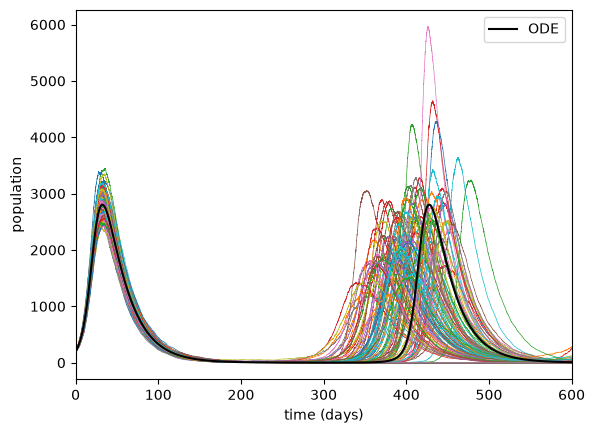

In [198]:
results_300 = seed_trajectory_scan(span = 300, t_end = 600)
filtered_results_300 = second_peak_filter(data = results_300, x_row = 0, y_row = 2, t_min = 200, t_max = 600, λ = 5, y_min = 100)
analyzed_filtered_results_300 = analysis(data = filtered_results_300, row =1, n = 300)

mean = 2399.774, std = 651.443, standard error = 20.600


c:\Users\mitch\OneDrive\Desktop\CHME-5137\CHME-5137-Code\.venv\Lib\site-packages\IPython\core\events.py:101: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)
c:\Users\mitch\OneDrive\Desktop\CHME-5137\CHME-5137-Code\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


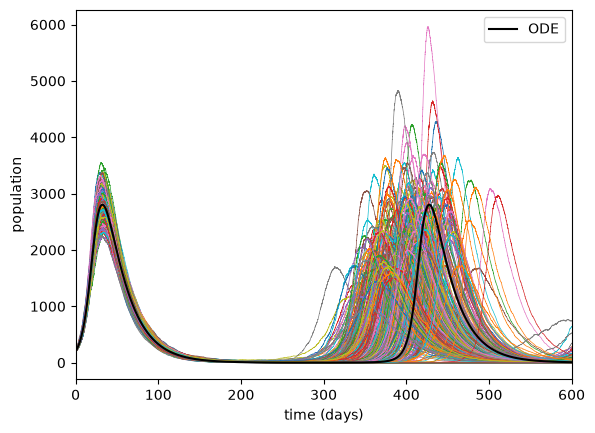

In [200]:
results_1000 = seed_trajectory_scan(span = 1000, t_end = 600)
filtered_results_1000 = second_peak_filter(data = results_1000, x_row = 0, y_row = 2, t_min = 200, t_max = 600, λ = 5, y_min = 100)
analyzed_filtered_results_1000 = analysis(data = filtered_results_1000, row =1, n = 1000)

mean = 2389.635, std = 590.991, standard error = 341.209


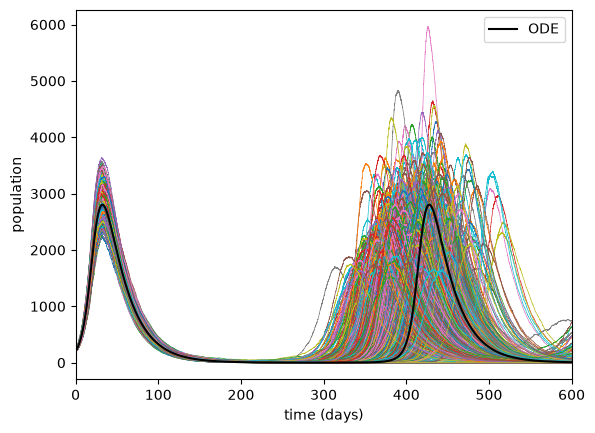

In [ ]:
results_3000 = seed_trajectory_scan(span = 3000, t_end = 600)
filtered_results_3000 = second_peak_filter(data = results_3000, x_row = 0, y_row = 2, t_min = 200, t_max = 600, λ = 5, y_min = 100)
analyzed_filtered_results_3000 = analysis(data = filtered_results_3000, row =1, n = 3000)

[np.float64(0.0), np.float64(70.39158477127484), np.float64(41.471912825208136), np.float64(20.600439692019567), np.float64(10.78996523406107)]


Text(0, 0.5, 'standard error (s/sqrt(n))')

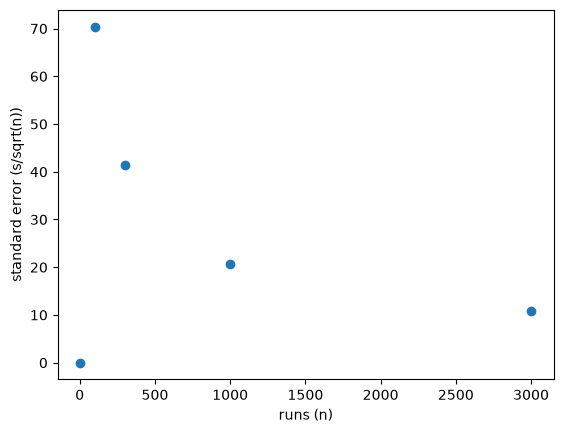

In [204]:
standard_errors = [analyzed_filtered_results_3[2],analyzed_filtered_results_100[2], analyzed_filtered_results_300[2], analyzed_filtered_results_1000[2], analyzed_filtered_results_3000[1]/np.sqrt(3000)]
number_of_runs = [3,100,300,1000,3000]
array = standard_errors, number_of_runs
print(array[0])
plt.plot(array[1], array[0], "o")
plt.xlabel("runs (n)")
plt.ylabel("standard error (s/sqrt(n))")

In [211]:
print(np.mean(filtered_results_3000[0]))
print(np.mean(filtered_results_3000[1]))
print(np.std(filtered_results_3000[1]))
print(analyzed_filtered_results_3000[1]/np.sqrt(3000))

401.5771158035714
2389.6349206349205
590.9907353391758
10.78996523406107


## 5. How likely is it that the foxes die out?

From your largest set of runs, what fraction have **no foxes left at day 600**?
That fraction $p$ estimates a probability. Its standard error is
$\sqrt{p(1-p)/N}$ for $N$ runs.

- Give the probability that the foxes die out before 600 days, with its uncertainty.
- How many runs would you need to know it to within ±1 percentage point? To within
  ±0.1?
- Plot a histogram of the times at which the foxes die out. When does it usually
  happen?

*Answer:*

a) Give the probability that the foxes die out before 600 days, with its uncertainty.

b) How many runs would you need to know it to within ±1 percentage point? To within ±0.1?

c) Plot a histogram of the times at which the foxes die out. When does it usually happen?

## 6. Your project

One paragraph. Is there any part of your project where the numbers are small
enough, or the events discrete and random enough, that a continuum model (an ODE or
a PDE) could mislead you, the way the ODE does about the foxes? Think about
molecules on a surface, cells, bubbles, particles, defects, failures. If there is,
what would the "events" and their rates be? If there isn't, why is a continuum model
good enough?

*Answer:*

## Stretch problems

**(a) Faster.** Time one trajectory. Then find where the time goes (`%prun`, or
time the pieces). Try Python's `random.random()` in place of `rng.random()`,
appending to lists versus filling a preallocated array, and recording only every
100th event. How much faster can you make it?

**(b) Bigger, on Explorer.** The `.py` paired with this notebook is a script.
Make a copy that runs 10,000 trajectories and saves the second-peak times and heights
and the extinction times with `np.savetxt`, and run it as a batch job on Explorer,
as in Lecture 9. Do your answers to tasks 4 and 5 hold up?

**(c) Is the random clock worth it?** Wikipedia notes that advancing the clock by
$\Delta t = 1/Q_k$ every step, instead of an exponentially distributed $\Delta t$, gives
"the same *average* time scale" (and that note is marked *citation needed*). Test it.
Make a copy of your `kmc` function that uses $\Delta t = 1/Q$, and run both versions
many times. Compare the probability that the foxes die out by day 600, the fraction of
runs with a second peak, and the mean time and height of that peak, each with its
standard error. Which differences are bigger than their uncertainty? How many runs did
you need before you could tell? (Several thousand of each; (a) and (b) help.) Why might
some quantities change and others not?

---

### When you're done

Restart & Run All. Check that every cell ran, in order, with no errors. Commit and
push. Then check on GitHub that your fork shows your latest commit, and that the
notebook displays with its plots.